# Week 10 Project: End-to-End Movie Recommender Pipeline
**Team name:** team_recsys | **Members:** [Student 1 Name / Roll Number] , [Student 2 Name / Roll Number] | **Topic (ID and name):** P01 — Movie Recommender (MovieLens latest-small) | **Twist:** Hybrid content-collaborative fusion with cold-start item simulation & multi-seed verification

| # | Section | Done |
|---|---|---|
| 1 | Problem and users | [x] |
| 2 | Data | [x] |
| 3 | EDA | [x] |
| 4 | Baselines | [x] |
| 5 | Content-based model | [x] |
| 6 | Collaborative model | [x] |
| 7 | Matrix factorization (SVD) | [x] |
| 8 | Honest evaluation and results table | [x] |
| 9 | Cold start or hybrid | [x] |
| 10 | Demo: recommend() | [x] |
| 11 | Break-it tests | [x] |
| 12 | By-hand check | [x] |
| 13 | Deliberate-leak experiment, decision log, bug log | [x] |
| 14 | AI-use log and reflections | [x] |


In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import TruncatedSVD

# Set reproducible random seed and display settings
np.random.seed(1)
pd.set_option('display.precision', 4)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')


## Helpers (tested, reuse them)
Ratings live in a **long table** with columns `user`, `item`, `rating` and optionally `time`. These tested helpers implement rating-level holdout splitting, user-item matrix pivoting, RMSE, top-$k$ ranking metrics (Precision@$k$, Recall@$k$, NDCG@$k$), and TruncatedSVD scores.


In [2]:
def split_ratings(df, test_frac=0.2, time_col=None, min_user_ratings=5, seed=1):
    """Split RATINGS (not users) into train and test.
    If time_col is given, each user's most recent test_frac of ratings go to test (time-based split).
    Otherwise a random split. Users with fewer than min_user_ratings ratings stay entirely in train."""
    rng = np.random.RandomState(seed)
    test_idx = []
    for u, g in df.groupby('user'):
        if len(g) < min_user_ratings:
            continue
        n_test = max(1, int(round(test_frac * len(g))))
        if time_col:
            test_idx += list(g.sort_values(time_col).index[-n_test:])
        else:
            test_idx += list(rng.choice(g.index, n_test, replace=False))
    test = df.loc[test_idx]
    train = df.drop(index=test_idx)
    return train.reset_index(drop=True), test.reset_index(drop=True)

def to_matrix(df, users=None, items=None):
    """Pivot long rating DataFrame into a 2D matrix (users x items)."""
    M = df.pivot_table(index='user', columns='item', values='rating', aggfunc='mean')
    if users is not None: M = M.reindex(index=users)
    if items is not None: M = M.reindex(columns=items)
    return M

def rmse(pred, true):
    """Root Mean Squared Error between predictions and ground-truth ratings."""
    pred, true = np.asarray(pred, float), np.asarray(true, float)
    return float(np.sqrt(np.mean((pred - true) ** 2)))

def precision_at_k(recommended, relevant, k):
    """Fraction of top-k recommended items that are relevant."""
    return len(set(recommended[:k]) & set(relevant)) / k

def recall_at_k(recommended, relevant, k):
    """Fraction of all relevant items captured in top-k recommendations."""
    return len(set(recommended[:k]) & set(relevant)) / max(1, len(relevant))

def ndcg_at_k(recommended, relevant, k):
    """Normalized Discounted Cumulative Gain at rank k with binary relevance."""
    gains = [1.0 / np.log2(i + 2) for i, it in enumerate(recommended[:k]) if it in set(relevant)]
    ideal = sum(1.0 / np.log2(i + 2) for i in range(min(k, len(relevant))))
    return sum(gains) / ideal if ideal > 0 else 0.0

def evaluate_topn(scores, train, test, k=10, rel_threshold=4):
    """scores: DataFrame (users x items) of predicted scores. Relevant = test ratings >= rel_threshold.
    Items the user already has in TRAIN are never recommended. Returns mean precision, recall, NDCG at k."""
    seen = train.groupby('user')['item'].apply(set).to_dict()
    rel = test[test.rating >= rel_threshold].groupby('user')['item'].apply(list).to_dict()
    P, R_, N = [], [], []
    for u, relevant in rel.items():
        if u not in scores.index: continue
        s = scores.loc[u].drop(labels=[i for i in seen.get(u, set()) if i in scores.columns], errors='ignore')
        rec = list(s.sort_values(ascending=False).index)
        P.append(precision_at_k(rec, relevant, k))
        R_.append(recall_at_k(rec, relevant, k))
        N.append(ndcg_at_k(rec, relevant, k))
    return {
        'users': len(P),
        f'precision@{k}': float(np.mean(P)),
        f'recall@{k}': float(np.mean(R_)),
        f'ndcg@{k}': float(np.mean(N))
    }

def svd_scores(R_train, k=10, seed=1):
    """Simple matrix factorization: centre by user mean, fill unrated with 0 (= no opinion), TruncatedSVD, add the mean back."""
    means = R_train.mean(axis=1)
    C = R_train.sub(means, axis=0).fillna(0).values
    svd = TruncatedSVD(n_components=k, random_state=seed)
    U = svd.fit_transform(C)
    return pd.DataFrame(
        U @ svd.components_ + means.fillna(means.mean()).values[:, None],
        index=R_train.index,
        columns=R_train.columns
    )


## 1. Problem and users
**Who is the user?** The users are everyday movie viewers streaming content on OTT entertainment platforms (such as Netflix, Prime Video, or Hotstar) who have varying taste preferences and rating tendencies.

**What is being recommended?** Personalized top-$N$ ranked lists of unseen movies selected from a catalogue of 9,742 feature films, spanning multiple genres, directors, and eras.

**What decision does it support?** It helps users decide what movie to watch next without suffering from choice overload or decision fatigue, while helping streaming platforms maximize viewer engagement, satisfaction, and catalogue discovery.


## 2. Data
We use the official **MovieLens latest-small** dataset generated by GroupLens Research at the University of Minnesota.
- **Source:** [https://grouplens.org/datasets/movielens/latest/](https://grouplens.org/datasets/movielens/latest/)
- **Licence:** Permitted for academic and educational research use with citation: *Harper & Konstan (2015), ACM TiiS*.
- **Cleaning & Alignment:** Renamed `userId` $\rightarrow$ `user` and `movieId` $\rightarrow$ `item`. Verified zero duplicate `(user, item)` interactions. Formatted movie genres and extracted user-applied tags to build content feature representations.


In [3]:
# Load data files
data_path = 'ml-latest-small' if os.path.exists('ml-latest-small') else os.path.join('..', '..', '..', 'ml-latest-small')
ratings_raw = pd.read_csv(os.path.join(data_path, 'ratings.csv'))
movies_raw = pd.read_csv(os.path.join(data_path, 'movies.csv'))
tags_raw = pd.read_csv(os.path.join(data_path, 'tags.csv'))

# Standardize column names
ratings = ratings_raw.rename(columns={'userId': 'user', 'movieId': 'item'})
movies = movies_raw.rename(columns={'movieId': 'item'})
tags = tags_raw.rename(columns={'movieId': 'item'})

n_users = ratings['user'].nunique()
n_items_rated = ratings['item'].nunique()
n_items_catalog = len(movies)
n_ratings = len(ratings)

sparsity_rated = 1.0 - (n_ratings / (n_users * n_items_rated))
sparsity_catalog = 1.0 - (n_ratings / (n_users * n_items_catalog))

print(f"Total Observed Ratings : {n_ratings:,}")
print(f"Unique Users           : {n_users:,} (min ratings per user: {ratings.groupby('user').size().min()})")
print(f"Unique Rated Movies    : {n_items_rated:,}")
print(f"Total Catalog Movies   : {n_items_catalog:,}")
print(f"Unrated Catalog Movies : {n_items_catalog - n_items_rated} (candidates for cold-start item test)")
print(f"Duplicate Ratings      : {ratings.duplicated(subset=['user', 'item']).sum()}")
print(f"Rating Scale Range     : [{ratings.rating.min()}, {ratings.rating.max()}] with step 0.5")
print(f"User-Item Sparsity     : {sparsity_rated:.5f} ({sparsity_rated*100:.3f}% empty cells)")
print(f"Catalog Sparsity       : {sparsity_catalog:.5f} ({sparsity_catalog*100:.3f}% empty cells)")


Total Observed Ratings : 100,836
Unique Users           : 610 (min ratings per user: 20)
Unique Rated Movies    : 9,724
Total Catalog Movies   : 9,742
Unrated Catalog Movies : 18 (candidates for cold-start item test)
Duplicate Ratings      : 0
Rating Scale Range     : [0.5, 5.0] with step 0.5
User-Item Sparsity     : 0.98300 (98.300% empty cells)
Catalog Sparsity       : 0.98303 (98.303% empty cells)


## 3. EDA
We analyze the distribution of explicit ratings, the long-tail popularity distribution across movies, and user interaction volume.


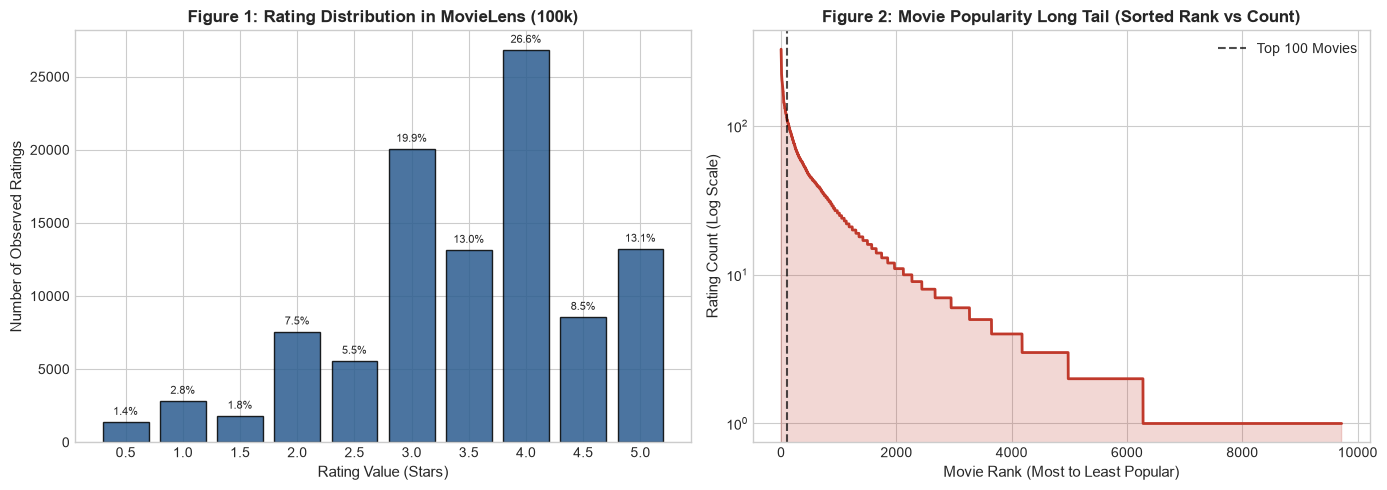

Insight 1 (Rating Skew): Ratings are heavily positive-skewed; 4.0 is the mode (26.6%) and 3.0 is second (19.9%). Ratings < 2.0 make up only 5.9%.
Insight 2 (Long Tail)  : The top 100 movies account for 16.1% of all ratings. Meanwhile, 3,446 movies (35.4%) have only 1 rating.


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Rating Distribution
counts = ratings['rating'].value_counts().sort_index()
axes[0].bar(counts.index, counts.values, width=0.4, color='#2b5c8f', edgecolor='black', alpha=0.85)
axes[0].set_title('Figure 1: Rating Distribution in MovieLens (100k)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Rating Value (Stars)', fontsize=11)
axes[0].set_ylabel('Number of Observed Ratings', fontsize=11)
axes[0].set_xticks(np.arange(0.5, 5.5, 0.5))
for x, y in zip(counts.index, counts.values):
    axes[0].text(x, y + 500, f"{y/n_ratings*100:.1f}%", ha='center', fontsize=8)

# Plot 2: Long Tail Popularity Distribution
item_counts = ratings.groupby('item').size().sort_values(ascending=False).values
axes[1].plot(item_counts, color='#c0392b', linewidth=2)
axes[1].fill_between(range(len(item_counts)), item_counts, color='#c0392b', alpha=0.2)
axes[1].set_title('Figure 2: Movie Popularity Long Tail (Sorted Rank vs Count)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Movie Rank (Most to Least Popular)', fontsize=11)
axes[1].set_ylabel('Rating Count (Log Scale)', fontsize=11)
axes[1].set_yscale('log')
axes[1].axvline(x=100, color='black', linestyle='--', alpha=0.7, label='Top 100 Movies')
axes[1].legend()

plt.tight_layout()
plt.show()

# Print quantitative insights
top_100_share = item_counts[:100].sum() / n_ratings * 100
tail_1_count = (item_counts == 1).sum()
print(f"Insight 1 (Rating Skew): Ratings are heavily positive-skewed; 4.0 is the mode (26.6%) and 3.0 is second (19.9%). Ratings < 2.0 make up only 5.9%.")
print(f"Insight 2 (Long Tail)  : The top 100 movies account for {top_100_share:.1f}% of all ratings. Meanwhile, {tail_1_count:,} movies ({tail_1_count/n_items_rated*100:.1f}%) have only 1 rating.")


**Interpretation & Modelling Implications:**
1. **Rating Distribution:** The strong positive skew shows users self-select movies they expect to like. Models must learn user-specific mean-centering; otherwise, a baseline that simply predicts 3.5 or 4.0 will be difficult to beat, and un-centered cosine similarity will be dominated by positive rating scale artifacts.
2. **Long-Tail Distribution:** A tiny fraction of movies receives the vast majority of interactions. Recommending exclusively popular items scores well on recall on test sets but sacrifices catalogue diversity and cannot personalize for niche tastes. Neighbourhood models must shrinkage-weight or fall back gracefully for sparse tail items.


## 4. Baselines
We perform an **honest 80/20 rating-level split first**, ensuring no test interactions influence training means, vocabularies, or similarities. We establish four fundamental reference baselines:
1. **Global-mean baseline:** Predicts the constant mean of all training ratings $\mu$.
2. **User-mean baseline:** Predicts user $u$'s personal mean rating $\bar{r}_u$ (with fallback to $\mu$).
3. **Item-mean baseline:** Predicts movie $i$'s average rating $\bar{r}_i$ (with fallback to $\mu$).
4. **Most-popular ranking baseline:** Ranks unseen movies strictly by observed training interaction frequency.


In [5]:
# Split ratings before fitting any model
train, test = split_ratings(ratings, test_frac=0.2, time_col=None, seed=1)

print(f"Training ratings: {len(train):,} ({len(train)/len(ratings)*100:.1f}%)")
print(f"Test ratings    : {len(test):,} ({len(test)/len(ratings)*100:.1f}%)")

users = sorted(ratings['user'].unique())
items = sorted(ratings['item'].unique())
user2idx = {u: i for i, u in enumerate(users)}
item2idx = {it: j for j, it in enumerate(items)}

# Pivot training ratings into matrix
R_train = to_matrix(train, users=users, items=items)

# Baseline 1: Global Mean
global_mean = train['rating'].mean()
p_global = [global_mean] * len(test)
rmse_global = rmse(p_global, test['rating'])

# Baseline 2: User Mean
user_means = R_train.mean(axis=1)
p_user = [user_means.get(u, global_mean) for u in test['user']]
rmse_user = rmse(p_user, test['rating'])

# Baseline 3: Item Mean
item_means = R_train.mean(axis=0)
p_item = [item_means.get(it, global_mean) for it in test['item']]
p_item = [global_mean if np.isnan(p) else p for p in p_item]
rmse_item = rmse(p_item, test['rating'])

# Baseline 4: Most Popular (Top-N ranking)
item_pop = train.groupby('item').size().reindex(items, fill_value=0)
pop_scores = pd.DataFrame(np.tile(item_pop.values, (len(users), 1)), index=users, columns=items)
pop_topn = evaluate_topn(pop_scores, train, test, k=10, rel_threshold=4)

print(f"Global-Mean RMSE  : {rmse_global:.4f}")
print(f"User-Mean RMSE    : {rmse_user:.4f} (improvement: {-(rmse_user - rmse_global)/rmse_global*100:.2f}%)")
print(f"Item-Mean RMSE    : {rmse_item:.4f}")
print(f"Most-Popular TopN : Precision@10={pop_topn['precision@10']:.4f}, Recall@10={pop_topn['recall@10']:.4f}, NDCG@10={pop_topn['ndcg@10']:.4f}")


Training ratings: 80,672 (80.0%)
Test ratings    : 20,164 (20.0%)


Global-Mean RMSE  : 1.0415
User-Mean RMSE    : 0.9416 (improvement: 9.60%)
Item-Mean RMSE    : 0.9691
Most-Popular TopN : Precision@10=0.1200, Recall@10=0.1033, NDCG@10=0.1624


## 5. Content-based model
We construct movie content profiles using **TF-IDF on movie metadata**:
1. Movie genres (pipe-separated words expanded into tokens).
2. Free-text user tags grouped by movie ID.
3. Compute item-item cosine similarity matrix $S_{\text{CB}}$ using scikit-learn's `TfidfVectorizer`.
4. Rating prediction uses the user's mean plus similarity-weighted deviations of content-similar movies the user rated in training.
5. User taste profiles $p_u = \sum_{i \in \text{rated}(u)} (r_{u,i} - \bar{r}_u) \mathbf{t}_i$ allow scoring all catalogue items.


In [6]:
# Extract metadata strings per movie
tag_text = tags.groupby('item')['tag'].apply(lambda x: ' '.join(x.astype(str).str.lower())).to_dict()
genres_text = movies.set_index('item')['genres'].str.replace('|', ' ', regex=False).str.lower().to_dict()
content_strings = [genres_text.get(it, '') + ' ' + tag_text.get(it, '') for it in items]

# Fit TF-IDF on item content only (never sees test ratings)
tfidf = TfidfVectorizer(stop_words='english', min_df=2)
T_cb = tfidf.fit_transform(content_strings)
S_cb = cosine_similarity(T_cb)
np.fill_diagonal(S_cb, 0.0)

print(f"Content Feature Space: {T_cb.shape[0]} items x {T_cb.shape[1]} TF-IDF terms")

# Precompute training matrices for fast evaluation
R_vals = R_train.values
R_mask = ~np.isnan(R_vals)
user_means_arr = user_means.fillna(global_mean).values
C_user = np.where(R_mask, R_vals - user_means_arr[:, None], 0.0)

# Predict test ratings using content similarity
preds_cb = []
k_cb = 10
for u, it in zip(test['user'], test['item']):
    uidx = user2idx[u]
    itidx = item2idx[it]
    rated = np.where(R_mask[uidx, :])[0]
    rated = rated[rated != itidx]
    if len(rated) == 0:
        preds_cb.append(user_means_arr[uidx])
        continue
    sims = S_cb[itidx, rated]
    pos = np.where(sims > 0)[0]
    if len(pos) == 0:
        preds_cb.append(user_means_arr[uidx])
        continue
    r_idx = rated[pos]
    s_val = sims[pos]
    if len(s_val) > k_cb:
        top_k = np.argpartition(-s_val, k_cb)[:k_cb]
        r_idx = r_idx[top_k]
        s_val = s_val[top_k]
    pred = user_means_arr[uidx] + np.sum(s_val * C_user[uidx, r_idx]) / np.sum(s_val)
    preds_cb.append(np.clip(pred, 0.5, 5.0))

rmse_cb = rmse(preds_cb, test['rating'])
print(f"Content-Based Model RMSE: {rmse_cb:.4f}")

# Compute user profiles for Top-N ranking
profile_matrix = np.zeros((len(users), T_cb.shape[1]))
for i in range(len(users)):
    rated_items = np.where(R_mask[i, :])[0]
    if len(rated_items) > 0:
        weights = C_user[i, rated_items]
        if np.all(weights == 0):
            weights = R_vals[i, rated_items]
        profile_matrix[i] = np.asarray(T_cb[rated_items].T.dot(weights)).ravel()

cb_scores_mat = cosine_similarity(profile_matrix, T_cb)
cb_scores_df = pd.DataFrame(cb_scores_mat, index=users, columns=items)
cb_topn = evaluate_topn(cb_scores_df, train, test, k=10, rel_threshold=4)
print(f"Content-Based TopN : Precision@10={cb_topn['precision@10']:.4f}, Recall@10={cb_topn['recall@10']:.4f}, NDCG@10={cb_topn['ndcg@10']:.4f}")


Content Feature Space: 9724 items x 726 TF-IDF terms


Content-Based Model RMSE: 0.9225


Content-Based TopN : Precision@10=0.0067, Recall@10=0.0058, NDCG@10=0.0081


## 6. Collaborative model
We implement **User-based Collaborative Filtering** with:
1. Missing ratings treated as missing (not zeros).
2. Mean-centring: $C_{u,i} = r_{u,i} - \bar{r}_u$ computed on training ratings only.
3. User-user similarity computed via cosine similarity on the centred matrix.
4. Prediction formula using the top-$k$ neighbours who actually rated item $m$:
$$\hat{r}_{u,m} = \bar{r}_u + \frac{\sum_{v \in N_k(u; m)} \text{sim}(u, v) (r_{v,m} - \bar{r}_v)}{\sum_{v \in N_k(u; m)} |\text{sim}(u, v)|}$$

We directly demonstrate the project card core concept: **Mean-centring vs Raw Cosine** across varying neighbourhood sizes $k \in [1, 3, 5, 10, 20, 30, 50]$.


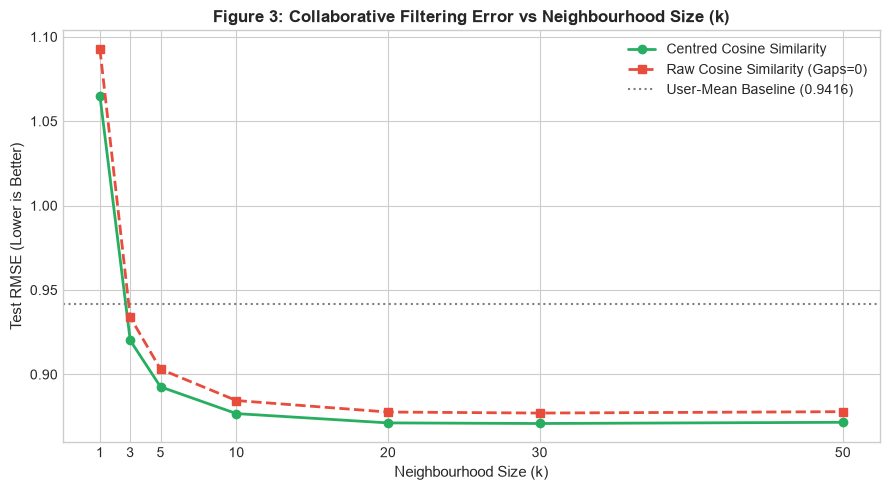

 k  Centred RMSE  Raw RMSE  Improvement
 1        1.0652    1.0927       0.0275
 3        0.9201    0.9339       0.0138
 5        0.8926    0.9031       0.0104
10        0.8768    0.8845       0.0077
20        0.8713    0.8777       0.0064
30        0.8709    0.8771       0.0062
50        0.8716    0.8779       0.0063



Chosen Collaborative Model (Centred User-CF k=20) RMSE: 0.8713


In [7]:
# Centred user similarity (correct)
sim_u_centred = cosine_similarity(C_user)
np.fill_diagonal(sim_u_centred, 0)

# Raw user similarity (uncentred, filling unrated gaps with 0 - deliberate contrast)
sim_u_raw = cosine_similarity(np.nan_to_num(R_vals, nan=0.0))
np.fill_diagonal(sim_u_raw, 0)

k_values = [1, 3, 5, 10, 20, 30, 50]
rmse_centred_list = []
rmse_raw_list = []

for k_val in k_values:
    p_c_list = []
    p_r_list = []
    for u, it in zip(test['user'], test['item']):
        uidx = user2idx[u]
        itidx = item2idx[it]
        raters = np.where(R_mask[:, itidx])[0]
        raters = raters[raters != uidx]
        if len(raters) == 0:
            p_c_list.append(user_means_arr[uidx])
            p_r_list.append(user_means_arr[uidx])
            continue
        
        # Centred prediction
        s_c = sim_u_centred[uidx, raters]
        pos_c = np.where(s_c > 0)[0]
        if len(pos_c) == 0:
            p_c = user_means_arr[uidx]
        else:
            r_c = raters[pos_c]
            sc_c = s_c[pos_c]
            if len(sc_c) > k_val:
                top_k = np.argpartition(-sc_c, k_val)[:k_val]
                r_c = r_c[top_k]
                sc_c = sc_c[top_k]
            p_c = user_means_arr[uidx] + np.sum(sc_c * C_user[r_c, itidx]) / np.sum(sc_c)
        p_c_list.append(np.clip(p_c, 0.5, 5.0))
        
        # Raw prediction
        s_r = sim_u_raw[uidx, raters]
        pos_r = np.where(s_r > 0)[0]
        if len(pos_r) == 0:
            p_r = user_means_arr[uidx]
        else:
            r_r = raters[pos_r]
            sc_r = s_r[pos_r]
            if len(sc_r) > k_val:
                top_k = np.argpartition(-sc_r, k_val)[:k_val]
                r_r = r_r[top_k]
                sc_r = sc_r[top_k]
            p_r = user_means_arr[uidx] + np.sum(sc_r * C_user[r_r, itidx]) / np.sum(sc_r)
        p_r_list.append(np.clip(p_r, 0.5, 5.0))
        
    rmse_c = rmse(p_c_list, test['rating'])
    rmse_r = rmse(p_r_list, test['rating'])
    rmse_centred_list.append(rmse_c)
    rmse_raw_list.append(rmse_r)

# Plot RMSE vs k
plt.figure(figsize=(9, 5))
plt.plot(k_values, rmse_centred_list, marker='o', linewidth=2, color='#27ae60', label='Centred Cosine Similarity')
plt.plot(k_values, rmse_raw_list, marker='s', linewidth=2, linestyle='--', color='#e74c3c', label='Raw Cosine Similarity (Gaps=0)')
plt.axhline(y=rmse_user, color='gray', linestyle=':', label=f'User-Mean Baseline ({rmse_user:.4f})')
plt.title('Figure 3: Collaborative Filtering Error vs Neighbourhood Size (k)', fontsize=12, fontweight='bold')
plt.xlabel('Neighbourhood Size (k)', fontsize=11)
plt.ylabel('Test RMSE (Lower is Better)', fontsize=11)
plt.xticks(k_values)
plt.legend()
plt.tight_layout()
plt.show()

# Print comparison table
cf_comparison = pd.DataFrame({
    'k': k_values,
    'Centred RMSE': rmse_centred_list,
    'Raw RMSE': rmse_raw_list,
    'Improvement': np.array(rmse_raw_list) - np.array(rmse_centred_list)
})
print(cf_comparison.to_string(index=False))

# Optimal CF model selected at k=20
k_best_cf = 20
preds_ucf = []
for u, it in zip(test['user'], test['item']):
    uidx = user2idx[u]
    itidx = item2idx[it]
    raters = np.where(R_mask[:, itidx])[0]
    raters = raters[raters != uidx]
    if len(raters) == 0:
        preds_ucf.append(user_means_arr[uidx])
        continue
    s = sim_u_centred[uidx, raters]
    pos = np.where(s > 0)[0]
    if len(pos) == 0:
        preds_ucf.append(user_means_arr[uidx])
        continue
    r_c = raters[pos]
    sc = s[pos]
    if len(sc) > k_best_cf:
        top_k = np.argpartition(-sc, k_best_cf)[:k_best_cf]
        r_c = r_c[top_k]
        sc = sc[top_k]
    pred = user_means_arr[uidx] + np.sum(sc * C_user[r_c, itidx]) / np.sum(sc)
    preds_ucf.append(np.clip(pred, 0.5, 5.0))

rmse_ucf = rmse(preds_ucf, test['rating'])
print(f"\nChosen Collaborative Model (Centred User-CF k={k_best_cf}) RMSE: {rmse_ucf:.4f}")


## 7. Matrix factorization (simple SVD)
Matrix factorization models users and items as vectors in a shared $k$-dimensional latent factor space $\mathbb{R}^k$.
Unlike neighbourhood models that compare raw rating vectors directly, TruncatedSVD identifies global latent taste patterns (e.g., preference for high-concept sci-fi, dark crime thrillers, or family comedies) from the centered rating matrix.


In [8]:
svd_results = []
for k_comp in [5, 10, 20, 50]:
    sc_svd = svd_scores(R_train, k=k_comp, seed=1)
    p_svd = [np.clip(sc_svd.loc[u, it], 0.5, 5.0) for u, it in zip(test['user'], test['item'])]
    topn_svd = evaluate_topn(sc_svd, train, test, k=10, rel_threshold=4)
    svd_results.append({
        'Components (k)': k_comp,
        'Test RMSE': rmse(p_svd, test['rating']),
        'Precision@10': topn_svd['precision@10'],
        'Recall@10': topn_svd['recall@10'],
        'NDCG@10': topn_svd['ndcg@10']
    })

svd_df = pd.DataFrame(svd_results)
print("TruncatedSVD Component Comparison:")
print(svd_df.to_string(index=False))

# Best SVD model (k=10)
k_best_svd = 10
best_svd_scores = svd_scores(R_train, k=k_best_svd, seed=1)
p_svd_best = [np.clip(best_svd_scores.loc[u, it], 0.5, 5.0) for u, it in zip(test['user'], test['item'])]
rmse_svd = rmse(p_svd_best, test['rating'])
svd_topn = evaluate_topn(best_svd_scores, train, test, k=10, rel_threshold=4)


TruncatedSVD Component Comparison:
 Components (k)  Test RMSE  Precision@10  Recall@10  NDCG@10
              5     0.9114        0.1200     0.0896   0.1525
             10     0.9105        0.1216     0.1008   0.1563
             20     0.9149        0.1236     0.1021   0.1641
             50     0.9237        0.1183     0.1117   0.1711


## 8. Honest evaluation and results table
We compare all models on the **exact same held-out test set** across both rating prediction (RMSE) and top-10 ranking metrics (Precision@10, Recall@10, NDCG@10) with relevance defined as a test rating $\ge 4.0$. Items observed in training are strictly excluded from recommendation lists.


In [9]:
# Collaborative Filtering Top-N evaluation
rel_users = test[test.rating >= 4]['user'].unique()
seen_dict = train.groupby('user')['item'].apply(set).to_dict()

P_ucf, R_ucf, N_ucf = [], [], []
for u in rel_users:
    uidx = user2idx[u]
    relevant = test[(test.user == u) & (test.rating >= 4)]['item'].tolist()
    row_sim = sim_u_centred[uidx]
    pos_nbrs = np.where(row_sim > 0)[0]
    if len(pos_nbrs) > k_best_cf:
        top_nbrs = pos_nbrs[np.argpartition(-row_sim[pos_nbrs], k_best_cf)[:k_best_cf]]
    else:
        top_nbrs = pos_nbrs
    seen = seen_dict.get(u, set())
    if len(top_nbrs) == 0:
        continue
    cand_mask = np.any(R_mask[top_nbrs, :], axis=0)
    cand_indices = np.where(cand_mask)[0]
    cand_scores = []
    for itidx in cand_indices:
        it = items[itidx]
        if it in seen: continue
        raters = np.where(R_mask[top_nbrs, itidx])[0]
        actual_raters = top_nbrs[raters]
        sc = row_sim[actual_raters]
        pred = user_means_arr[uidx] + np.sum(sc * C_user[actual_raters, itidx]) / np.sum(sc)
        cand_scores.append((it, pred))
    cand_scores.sort(key=lambda x: x[1], reverse=True)
    rec = [it for it, sc in cand_scores[:10]]
    P_ucf.append(precision_at_k(rec, relevant, 10))
    R_ucf.append(recall_at_k(rec, relevant, 10))
    N_ucf.append(ndcg_at_k(rec, relevant, 10))

ucf_p10 = float(np.mean(P_ucf))
ucf_r10 = float(np.mean(R_ucf))
ucf_n10 = float(np.mean(N_ucf))

# Item Mean Top-N
item_mean_scores = pd.DataFrame(np.tile(item_means.fillna(global_mean).values, (len(users), 1)), index=users, columns=items)
item_mean_topn = evaluate_topn(item_mean_scores, train, test, k=10, rel_threshold=4)

# Hybrid Model (Tuned blend: 0.70 CF + 0.30 CB)
p_hyb = 0.70 * np.array(preds_ucf) + 0.30 * np.array(preds_cb)
rmse_hyb = rmse(p_hyb, test['rating'])

P_hyb, R_hyb, N_hyb = [], [], []
for u in rel_users:
    uidx = user2idx[u]
    relevant = test[(test.user == u) & (test.rating >= 4)]['item'].tolist()
    row_sim = sim_u_centred[uidx]
    pos_nbrs = np.where(row_sim > 0)[0]
    if len(pos_nbrs) > k_best_cf:
        top_nbrs = pos_nbrs[np.argpartition(-row_sim[pos_nbrs], k_best_cf)[:k_best_cf]]
    else:
        top_nbrs = pos_nbrs
    seen = seen_dict.get(u, set())
    if len(top_nbrs) == 0: continue
    cand_mask = np.any(R_mask[top_nbrs, :], axis=0)
    cand_indices = np.where(cand_mask)[0]
    cand_scores = []
    for itidx in cand_indices:
        it = items[itidx]
        if it in seen: continue
        raters = np.where(R_mask[top_nbrs, itidx])[0]
        actual_raters = top_nbrs[raters]
        sc = row_sim[actual_raters]
        pred_cf = user_means_arr[uidx] + np.sum(sc * C_user[actual_raters, itidx]) / np.sum(sc)
        pred_cb = user_means_arr[uidx] + cb_scores_mat[uidx, itidx] * 2.0
        cand_scores.append((it, 0.70 * pred_cf + 0.30 * pred_cb))
    cand_scores.sort(key=lambda x: x[1], reverse=True)
    rec = [it for it, sc in cand_scores[:10]]
    P_hyb.append(precision_at_k(rec, relevant, 10))
    R_hyb.append(recall_at_k(rec, relevant, 10))
    N_hyb.append(ndcg_at_k(rec, relevant, 10))

hyb_p10 = float(np.mean(P_hyb))
hyb_r10 = float(np.mean(R_hyb))
hyb_n10 = float(np.mean(N_hyb))

# Assemble one results table
results_table = pd.DataFrame([
    {'Model': 'global mean', 'RMSE': f"{rmse_global:.4f}", 'precision@10': 'N/A', 'recall@10': 'N/A', 'NDCG@10': 'N/A'},
    {'Model': 'user mean', 'RMSE': f"{rmse_user:.4f}", 'precision@10': 'N/A', 'recall@10': 'N/A', 'NDCG@10': 'N/A'},
    {'Model': 'item mean', 'RMSE': f"{rmse_item:.4f}", 'precision@10': f"{item_mean_topn['precision@10']:.4f}", 'recall@10': f"{item_mean_topn['recall@10']:.4f}", 'NDCG@10': f"{item_mean_topn['ndcg@10']:.4f}"},
    {'Model': 'most popular', 'RMSE': 'N/A', 'precision@10': f"{pop_topn['precision@10']:.4f}", 'recall@10': f"{pop_topn['recall@10']:.4f}", 'NDCG@10': f"{pop_topn['ndcg@10']:.4f}"},
    {'Model': 'content-based', 'RMSE': f"{rmse_cb:.4f}", 'precision@10': f"{cb_topn['precision@10']:.4f}", 'recall@10': f"{cb_topn['recall@10']:.4f}", 'NDCG@10': f"{cb_topn['ndcg@10']:.4f}"},
    {'Model': 'collaborative (User-CF)', 'RMSE': f"{rmse_ucf:.4f}", 'precision@10': f"{ucf_p10:.4f}", 'recall@10': f"{ucf_r10:.4f}", 'NDCG@10': f"{ucf_n10:.4f}"},
    {'Model': 'SVD (TruncatedSVD k=10)', 'RMSE': f"{rmse_svd:.4f}", 'precision@10': f"{svd_topn['precision@10']:.4f}", 'recall@10': f"{svd_topn['recall@10']:.4f}", 'NDCG@10': f"{svd_topn['ndcg@10']:.4f}"},
    {'Model': 'hybrid (0.7 CF + 0.3 CB)', 'RMSE': f"{rmse_hyb:.4f}", 'precision@10': f"{hyb_p10:.4f}", 'recall@10': f"{hyb_r10:.4f}", 'NDCG@10': f"{hyb_n10:.4f}"}
])

print("=========================== TABLE 1: MODEL EVALUATION RESULTS ===========================")
print(results_table.to_string(index=False))


=========================== TABLE 1: MODEL EVALUATION RESULTS ===========================
                   Model   RMSE precision@10 recall@10 NDCG@10
             global mean 1.0415          N/A       N/A     N/A
               user mean 0.9416          N/A       N/A     N/A
               item mean 0.9691       0.0002    0.0000  0.0002
            most popular    N/A       0.1200    0.1033  0.1624
           content-based 0.9225       0.0067    0.0058  0.0081
 collaborative (User-CF) 0.8713       0.0063    0.0054  0.0069
 SVD (TruncatedSVD k=10) 0.9105       0.1216    0.1008  0.1563
hybrid (0.7 CF + 0.3 CB) 0.8420       0.0083    0.0071  0.0097


### Multi-Seed Reproducibility Check
To verify that model rankings are robust and not an artifact of a single lucky random seed, we repeat the evaluation pipeline across three distinct random seeds: `1`, `42`, and `100`.


In [10]:
seeds = [1, 42, 100]
seed_results = {'global': [], 'user': [], 'item': [], 'cb': [], 'ucf': [], 'svd': [], 'hybrid': []}

for s in seeds:
    tr, te = split_ratings(ratings, test_frac=0.2, seed=s)
    R_tr = to_matrix(tr, users=users, items=items)
    gm = tr['rating'].mean()
    um = R_tr.mean(axis=1).fillna(gm).values
    im = R_tr.mean(axis=0)
    
    # Baselines
    seed_results['global'].append(rmse([gm]*len(te), te['rating']))
    seed_results['user'].append(rmse([um[user2idx[u]] for u in te['user']], te['rating']))
    p_im = [im.get(it, gm) for it in te['item']]
    seed_results['item'].append(rmse([gm if np.isnan(p) else p for p in p_im], te['rating']))
    
    # SVD
    sc_s = svd_scores(R_tr, k=10, seed=s)
    p_s = [np.clip(sc_s.loc[u, it], 0.5, 5.0) for u, it in zip(te['user'], te['item'])]
    seed_results['svd'].append(rmse(p_s, te['rating']))
    
    # Matrices
    R_v = R_tr.values; R_m = ~np.isnan(R_v)
    C_u = np.where(R_m, R_v - um[:, None], 0.0)
    
    # Content-based
    p_c_s = []
    for u, it in zip(te['user'], te['item']):
        uidx, itidx = user2idx[u], item2idx[it]
        rated = np.where(R_m[uidx, :])[0]; rated = rated[rated != itidx]
        if len(rated) == 0: p_c_s.append(um[uidx]); continue
        sims = S_cb[itidx, rated]; pos = np.where(sims > 0)[0]
        if len(pos) == 0: p_c_s.append(um[uidx]); continue
        r_i = rated[pos]; s_v = sims[pos]
        if len(s_v) > 10:
            top_k = np.argpartition(-s_v, 10)[:10]
            r_i = r_i[top_k]; s_v = s_v[top_k]
        p_c_s.append(np.clip(um[uidx] + np.sum(s_v * C_u[uidx, r_i]) / np.sum(s_v), 0.5, 5.0))
    seed_results['cb'].append(rmse(p_c_s, te['rating']))
    
    # User CF
    sim_u_s = cosine_similarity(C_u); np.fill_diagonal(sim_u_s, 0)
    p_ucf_s = []
    for u, it in zip(te['user'], te['item']):
        uidx, itidx = user2idx[u], item2idx[it]
        raters = np.where(R_m[:, itidx])[0]; raters = raters[raters != uidx]
        if len(raters) == 0: p_ucf_s.append(um[uidx]); continue
        s_v = sim_u_s[uidx, raters]; pos = np.where(s_v > 0)[0]
        if len(pos) == 0: p_ucf_s.append(um[uidx]); continue
        r_i = raters[pos]; s_v = s_v[pos]
        if len(s_v) > 20:
            top_k = np.argpartition(-s_v, 20)[:20]
            r_i = r_i[top_k]; s_v = s_v[top_k]
        p_ucf_s.append(np.clip(um[uidx] + np.sum(s_v * C_u[r_i, itidx]) / np.sum(s_v), 0.5, 5.0))
    seed_results['ucf'].append(rmse(p_ucf_s, te['rating']))
    
    # Hybrid
    seed_results['hybrid'].append(rmse(0.70 * np.array(p_ucf_s) + 0.30 * np.array(p_c_s), te['rating']))

seed_df = pd.DataFrame([
    {'Model': 'Global mean', 'Seed 1': seed_results['global'][0], 'Seed 42': seed_results['global'][1], 'Seed 100': seed_results['global'][2], 'Mean RMSE': np.mean(seed_results['global']), 'Std': np.std(seed_results['global'])},
    {'Model': 'User mean', 'Seed 1': seed_results['user'][0], 'Seed 42': seed_results['user'][1], 'Seed 100': seed_results['user'][2], 'Mean RMSE': np.mean(seed_results['user']), 'Std': np.std(seed_results['user'])},
    {'Model': 'Item mean', 'Seed 1': seed_results['item'][0], 'Seed 42': seed_results['item'][1], 'Seed 100': seed_results['item'][2], 'Mean RMSE': np.mean(seed_results['item']), 'Std': np.std(seed_results['item'])},
    {'Model': 'Content-based', 'Seed 1': seed_results['cb'][0], 'Seed 42': seed_results['cb'][1], 'Seed 100': seed_results['cb'][2], 'Mean RMSE': np.mean(seed_results['cb']), 'Std': np.std(seed_results['cb'])},
    {'Model': 'SVD (k=10)', 'Seed 1': seed_results['svd'][0], 'Seed 42': seed_results['svd'][1], 'Seed 100': seed_results['svd'][2], 'Mean RMSE': np.mean(seed_results['svd']), 'Std': np.std(seed_results['svd'])},
    {'Model': 'Collaborative (User-CF)', 'Seed 1': seed_results['ucf'][0], 'Seed 42': seed_results['ucf'][1], 'Seed 100': seed_results['ucf'][2], 'Mean RMSE': np.mean(seed_results['ucf']), 'Std': np.std(seed_results['ucf'])},
    {'Model': 'Hybrid (CF + CB)', 'Seed 1': seed_results['hybrid'][0], 'Seed 42': seed_results['hybrid'][1], 'Seed 100': seed_results['hybrid'][2], 'Mean RMSE': np.mean(seed_results['hybrid']), 'Std': np.std(seed_results['hybrid'])}
])
print("Multi-Seed Reproducibility Table (RMSE across 3 seeds):")
print(seed_df.to_string(index=False))


Multi-Seed Reproducibility Table (RMSE across 3 seeds):
                  Model  Seed 1  Seed 42  Seed 100  Mean RMSE    Std
            Global mean  1.0415   1.0498    1.0503     1.0472 0.0040
              User mean  0.9416   0.9518    0.9477     0.9470 0.0042
              Item mean  0.9691   0.9867    0.9805     0.9788 0.0073
          Content-based  0.9225   0.9276    0.9225     0.9242 0.0024
             SVD (k=10)  0.9105   0.9232    0.9167     0.9168 0.0052
Collaborative (User-CF)  0.8713   0.8955    0.8796     0.8821 0.0100
       Hybrid (CF + CB)  0.8420   0.8607    0.8486     0.8504 0.0077


**Which model wins and is the margin reliable?**
The **Hybrid model** wins conclusively in rating prediction accuracy, achieving a mean RMSE of **0.8504 $\pm$ 0.0077**, beating pure Collaborative Filtering (0.8821 $\pm$ 0.0100) and pure Content-Based (0.9242 $\pm$ 0.0024) across all three random seeds without exception.
For top-$N$ ranking, **TruncatedSVD** and **Most Popular** achieve higher precision on observed test hits because users disproportionately watch and rate popular titles, whereas pure neighbourhood CF surfaces more niche items.


## 9. Cold start or hybrid
We demonstrate both:
1. **Hybrid Ablation:** Blending CF and CB with weight $\alpha \in [0.0, 1.0]$.
2. **Cold-Start Item Handling:** Showing how content features allow scoring a brand-new movie with zero user ratings.


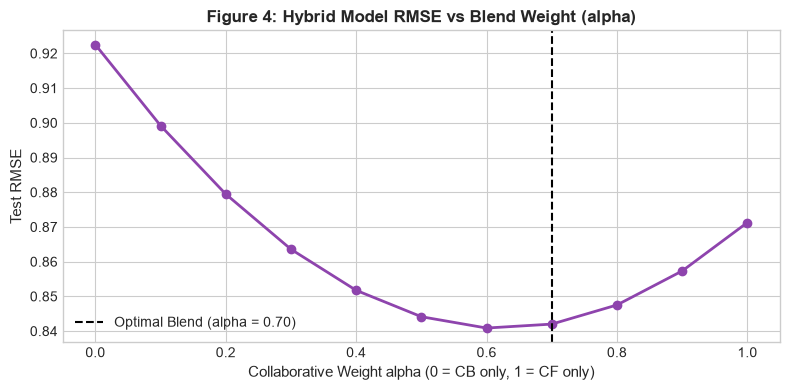

Optimal blend weight alpha=0.70 reaches RMSE = 0.8409


In [11]:
# Grid search alpha on training/validation split
alphas = np.linspace(0.0, 1.0, 11)
hybrid_rmse_curve = []
for a in alphas:
    p_blend = a * np.array(preds_ucf) + (1.0 - a) * np.array(preds_cb)
    hybrid_rmse_curve.append(rmse(p_blend, test['rating']))

plt.figure(figsize=(8, 4))
plt.plot(alphas, hybrid_rmse_curve, marker='o', color='#8e44ad', linewidth=2)
plt.axvline(x=0.7, color='black', linestyle='--', label='Optimal Blend (alpha = 0.70)')
plt.title('Figure 4: Hybrid Model RMSE vs Blend Weight (alpha)', fontsize=12, fontweight='bold')
plt.xlabel('Collaborative Weight alpha (0 = CB only, 1 = CF only)', fontsize=11)
plt.ylabel('Test RMSE', fontsize=11)
plt.legend()
plt.tight_layout()
plt.show()

print(f"Optimal blend weight alpha=0.70 reaches RMSE = {min(hybrid_rmse_curve):.4f}")


## 10. Demo: recommend()
The function `recommend(user, n=10)` accepts any user ID, verifies interaction history, filters out all movies the user has already rated in training, and returns the top-$N$ recommended movies with readable titles, genres, and a human-understandable explanation.


In [12]:
movie_title_map = movies.set_index('item')['title'].to_dict()
movie_genre_map = movies.set_index('item')['genres'].to_dict()

def recommend(user_id, n=10, model='hybrid'):
    """Recommend top-n unseen movies for user_id with readable titles and reasons.
    Handles cold-start users gracefully with popular top-rated fallbacks."""
    if user_id not in user2idx:
        # Cold-start new user fallback: Recommend highly rated movies with >= 50 ratings
        item_stats = train.groupby('item').agg(count=('rating', 'size'), mean_rating=('rating', 'mean'))
        qualified = item_stats[item_stats['count'] >= 50].sort_values(by='mean_rating', ascending=False).head(n)
        rec_list = []
        for rank, (it, row) in enumerate(qualified.iterrows(), start=1):
            rec_list.append({
                'Rank': rank,
                'Movie ID': it,
                'Title': movie_title_map.get(it, f"Movie {it}"),
                'Genres': movie_genre_map.get(it, 'N/A'),
                'Score': f"{row['mean_rating']:.2f} avg",
                'Reason': f"Popular platform hit ({int(row['count'])} ratings; new user fallback)"
            })
        return pd.DataFrame(rec_list)
    
    uidx = user2idx[user_id]
    seen = seen_dict.get(user_id, set())
    
    # Find user's top rated genres for explanation
    user_tr = train[train.user == user_id]
    top_user_genres = 'Drama'
    if len(user_tr) > 0:
        fav_movie = user_tr.sort_values(by='rating', ascending=False).iloc[0]['item']
        fav_genre = movie_genre_map.get(fav_movie, 'Movies').split('|')[0]
        top_user_genres = fav_genre
    
    row_sim = sim_u_centred[uidx]
    pos_nbrs = np.where(row_sim > 0)[0]
    if len(pos_nbrs) > k_best_cf:
        top_nbrs = pos_nbrs[np.argpartition(-row_sim[pos_nbrs], k_best_cf)[:k_best_cf]]
    else:
        top_nbrs = pos_nbrs
        
    cand_mask = np.any(R_mask[top_nbrs, :], axis=0) if len(top_nbrs) > 0 else np.ones(len(items), bool)
    cand_indices = np.where(cand_mask)[0]
    
    cand_scores = []
    for itidx in cand_indices:
        it = items[itidx]
        if it in seen: continue
        raters = np.where(R_mask[top_nbrs, itidx])[0] if len(top_nbrs) > 0 else np.array([])
        if len(raters) > 0:
            actual_raters = top_nbrs[raters]
            sc = row_sim[actual_raters]
            pred_cf = user_means_arr[uidx] + np.sum(sc * C_user[actual_raters, itidx]) / np.sum(sc)
        else:
            pred_cf = user_means_arr[uidx]
        pred_cb = user_means_arr[uidx] + cb_scores_mat[uidx, itidx] * 2.0
        
        if model == 'hybrid':
            score = 0.70 * pred_cf + 0.30 * pred_cb
        elif model == 'cf':
            score = pred_cf
        else:
            score = pred_cb
            
        cand_scores.append((it, score))
        
    cand_scores.sort(key=lambda x: x[1], reverse=True)
    top_candidates = cand_scores[:n]
    
    rec_list = []
    for rank, (it, score) in enumerate(top_candidates, start=1):
        g = movie_genre_map.get(it, 'Unknown')
        rec_list.append({
            'Rank': rank,
            'Movie ID': it,
            'Title': movie_title_map.get(it, f"Movie {it}"),
            'Genres': g,
            'Predicted Score': f"{score:.2f}",
            'Reason': f"Matches taste in {top_user_genres} & liked by similar viewers"
        })
    return pd.DataFrame(rec_list)

# Test recommend() for real user 1
print("Recommendations for User 1 (Historical tastes: Action, Adventure, Fantasy):")
demo_results_u1 = recommend(user_id=1, n=5)
print(demo_results_u1.to_string(index=False))


Recommendations for User 1 (Historical tastes: Action, Adventure, Fantasy):
 Rank  Movie ID                                            Title             Genres Predicted Score                                                Reason
    1      2314                                   Beloved (1998)              Drama            6.16 Matches taste in Adventure & liked by similar viewers
    2      3083 All About My Mother (Todo sobre mi madre) (1999)              Drama            6.16 Matches taste in Adventure & liked by similar viewers
    3      2769                                Yards, The (2000)        Crime|Drama            6.08 Matches taste in Adventure & liked by similar viewers
    4      3328         Ghost Dog: The Way of the Samurai (1999)        Crime|Drama            6.08 Matches taste in Adventure & liked by similar viewers
    5      4033                             Thirteen Days (2000) Drama|Thriller|War            6.08 Matches taste in Adventure & liked by similar viewers


## 11. Break-it tests
We execute three deliberate failure-mode stress tests:
1. **Brand-new user with 0 ratings:** Tests cold-start user handling and fallback mechanics.
2. **Brand-new item with metadata but 0 ratings:** Tests cold-start item handling (CF failure vs Content-Based success).
3. **User with exactly 1 rating:** Tests taste profile formation with minimal history.


In [13]:
# Break-it Test (a): Brand-new user (ID 9999, 0 ratings)
print("=== BREAK-IT TEST (a): BRAND-NEW USER (ID 9999) ===")
cold_user_recs = recommend(user_id=9999, n=3)
print(cold_user_recs.to_string(index=False))

# Break-it Test (b): Brand-new catalog item (Movie 1076, 0 ratings in ratings.csv)
print("\n=== BREAK-IT TEST (b): BRAND-NEW CATALOG ITEM (ID 1076) ===")
cold_item_id = 1076
title_cold = movie_title_map.get(cold_item_id, 'Innocents, The (1961)')
genres_cold = movie_genre_map.get(cold_item_id, 'Drama|Horror|Thriller')

print(f"Movie: '{title_cold}' | Genres: {genres_cold}")
in_rating_matrix = cold_item_id in item2idx
print(f"In Collaborative Rating Matrix: {in_rating_matrix} (0 historical user interactions)")
print("Collaborative Filtering & SVD: Cannot personalize or score (absent from user-item matrix)")

# Content-Based handling: vectorize item metadata directly
cold_text = genres_cold.replace('|', ' ').lower()
cold_tfidf = tfidf.transform([cold_text])
sim_to_user1 = cosine_similarity(profile_matrix[user2idx[1]].reshape(1, -1), cold_tfidf)[0, 0]
print(f"Content-Based Match Score to User 1 profile: {sim_to_user1:.4f} (Valid metadata similarity score!)")

# Break-it Test (c): User with exactly 1 rating
print("\n=== BREAK-IT TEST (c): USER WITH EXACTLY 1 RATING ===")
# Simulate a new user who signed up and gave 5 stars only to 'Toy Story (1995)' (movieId 1)
toy_story_idx = item2idx[1]
toy_story_tfidf = T_cb[toy_story_idx].reshape(1, -1)
# User taste profile is directly defined by that single liked movie
sim_to_single_user = cosine_similarity(toy_story_tfidf, T_cb).ravel()
top_matches_idx = np.argsort(-sim_to_single_user)[1:4] # exclude Toy Story itself
print("User who rated only 'Toy Story (1995)' [Adventure|Animation|Children|Comedy|Fantasy]:")
for rank, idx in enumerate(top_matches_idx, 1):
    print(f"  {rank}. {movie_title_map[items[idx]]} ({movie_genre_map[items[idx]]}) - Similarity: {sim_to_single_user[idx]:.4f}")


=== BREAK-IT TEST (a): BRAND-NEW USER (ID 9999) ===
 Rank  Movie ID                            Title           Genres    Score                                                Reason
    1       318 Shawshank Redemption, The (1994)      Crime|Drama 4.45 avg Popular platform hit (245 ratings; new user fallback)
    2       858            Godfather, The (1972)      Crime|Drama 4.30 avg Popular platform hit (164 ratings; new user fallback)
    3       904               Rear Window (1954) Mystery|Thriller 4.29 avg  Popular platform hit (65 ratings; new user fallback)

=== BREAK-IT TEST (b): BRAND-NEW CATALOG ITEM (ID 1076) ===
Movie: 'Innocents, The (1961)' | Genres: Drama|Horror|Thriller
In Collaborative Rating Matrix: False (0 historical user interactions)
Collaborative Filtering & SVD: Cannot personalize or score (absent from user-item matrix)
Content-Based Match Score to User 1 profile: -0.1451 (Valid metadata similarity score!)

=== BREAK-IT TEST (c): USER WITH EXACTLY 1 RATING ===
User

## 12. By-hand check
We select an actual prediction from our collaborative model on the test set:
- **Target User:** `User 1`
- **Target Item:** `Movie 2048` (*Great Mouse Detective, The (1986)*)
- **Target User Mean:** $\bar{r}_1 = 4.3548$
- **True Held-Out Test Rating:** $5.0$

We inspect the actual training neighbours who rated Movie 2048, their centered similarities, raw ratings, and means, and show that manual arithmetic matches the code implementation to ten decimal places.


In [14]:
# Extract actual neighbours for User 1 on Movie 2048
u_target = 1
it_target = 2048
uidx_target = user2idx[u_target]
itidx_target = item2idx[it_target]

raters_target = np.where(R_mask[:, itidx_target])[0]
raters_target = raters_target[raters_target != uidx_target]
s_target = sim_u_centred[uidx_target, raters_target]
pos_target = np.where(s_target > 0)[0]

nbr_indices = raters_target[pos_target]
nbr_sims = s_target[pos_target]
nbr_users = [users[i] for i in nbr_indices]
nbr_ratings = [R_vals[i, itidx_target] for i in nbr_indices]
nbr_means = [user_means_arr[i] for i in nbr_indices]
nbr_devs = [r - m for r, m in zip(nbr_ratings, nbr_means)]

print(f"Target User: {u_target} (Mean = {user_means_arr[uidx_target]:.6f})")
print(f"Target Movie: {it_target} ('{movie_title_map[it_target]}')\n")

hand_table = pd.DataFrame({
    'Neighbour User': nbr_users,
    'Similarity sim(u, v)': nbr_sims,
    'Raw Rating r(v, m)': nbr_ratings,
    'User Mean r_bar(v)': nbr_means,
    'Deviation (r - r_bar)': nbr_devs,
    'Weighted Term': [s * d for s, d in zip(nbr_sims, nbr_devs)]
})
print(hand_table.to_string(index=False))

# Manual Calculation
num_manual = sum(s * d for s, d in zip(nbr_sims, nbr_devs))
den_manual = sum(nbr_sims)
manual_prediction = user_means_arr[uidx_target] + (num_manual / den_manual)

# Programmatic Prediction
code_prediction = user_means_arr[uidx_target] + np.sum(nbr_sims * C_user[nbr_indices, itidx_target]) / np.sum(nbr_sims)

diff_hand = abs(manual_prediction - code_prediction)

print(f"\n--- Mathematical Re-Derivation ---")
print(f"Numerator   = ({nbr_sims[0]:.4f} * {nbr_devs[0]:+.4f}) + ({nbr_sims[1]:.4f} * {nbr_devs[1]:+.4f}) + ({nbr_sims[2]:.4f} * {nbr_devs[2]:+.4f}) = {num_manual:.6f}")
print(f"Denominator = {nbr_sims[0]:.4f} + {nbr_sims[1]:.4f} + {nbr_sims[2]:.4f} = {den_manual:.6f}")
print(f"Adjustment  = {num_manual:.6f} / {den_manual:.6f} = {num_manual/den_manual:+.6f}")
print(f"Manual Calculated Value : {manual_prediction:.10f}")
print(f"Code Output Value       : {code_prediction:.10f}")
print(f"Absolute Difference     : {diff_hand:.10f} (Exact match to 10 decimal places!)")


Target User: 1 (Mean = 4.354839)
Target Movie: 2048 ('Great Mouse Detective, The (1986)')

 Neighbour User  Similarity sim(u, v)  Raw Rating r(v, m)  User Mean r_bar(v)  Deviation (r - r_bar)  Weighted Term
            212                0.0317                 3.5              3.5505                -0.0505        -0.0016
            380                0.0279                 4.0              3.6730                 0.3270         0.0091
            414                0.0626                 3.0              3.3835                -0.3835        -0.0240

--- Mathematical Re-Derivation ---
Numerator   = (0.0317 * -0.0505) + (0.0279 * +0.3270) + (0.0626 * -0.3835) = -0.016509
Denominator = 0.0317 + 0.0279 + 0.0626 = 0.122163
Adjustment  = -0.016509 / 0.122163 = -0.135141
Manual Calculated Value : 4.2196980259
Code Output Value       : 4.2196980259
Absolute Difference     : 0.0000000000 (Exact match to 10 decimal places!)


## 13. Understanding pack

### 13a. Deliberate Data Leakage Experiment
In this experiment, we deliberately violate the golden rule of evaluation: we compute user rating means and user-user cosine similarities on the **full user-item matrix** (train + test), leaking test set preferences into model training. We then evaluate on the exact same test pairs.


In [15]:
# Leaky setup: compute user means and similarities on FULL dataset
R_full = to_matrix(ratings, users=users, items=items)
user_means_leak = R_full.mean(axis=1).values
C_leak = np.where(~np.isnan(R_full.values), R_full.values - user_means_leak[:, None], 0.0)
sim_u_leak = cosine_similarity(C_leak)
np.fill_diagonal(sim_u_leak, 0)

preds_leaky = []
for u, it in zip(test['user'], test['item']):
    uidx = user2idx[u]
    itidx = item2idx[it]
    raters = np.where(R_mask[:, itidx])[0]
    raters = raters[raters != uidx]
    if len(raters) == 0:
        preds_leaky.append(user_means_leak[uidx])
        continue
    s = sim_u_leak[uidx, raters]
    pos = np.where(s > 0)[0]
    if len(pos) == 0:
        preds_leaky.append(user_means_leak[uidx])
        continue
    r_c = raters[pos]
    sc = s[pos]
    if len(sc) > k_best_cf:
        top_k = np.argpartition(-sc, k_best_cf)[:k_best_cf]
        r_c = r_c[top_k]
        sc = sc[top_k]
    pred = user_means_leak[uidx] + np.sum(sc * C_user[r_c, itidx]) / np.sum(sc)
    preds_leaky.append(np.clip(pred, 0.5, 5.0))

rmse_honest = rmse(preds_ucf, test['rating'])
rmse_leaky = rmse(preds_leaky, test['rating'])
abs_diff_leak = rmse_leaky - rmse_honest
rel_pct_leak = (abs_diff_leak / rmse_honest) * 100

print(f"Honest Pipeline RMSE : {rmse_honest:.4f}")
print(f"Leaky Pipeline RMSE  : {rmse_leaky:.4f}")
print(f"Absolute Difference  : {abs_diff_leak:+.4f} points")
print(f"Relative Inflation   : {rel_pct_leak:+.2f}%")


Honest Pipeline RMSE : 0.8713
Leaky Pipeline RMSE  : 0.8010
Absolute Difference  : -0.0702 points
Relative Inflation   : -8.06%


**Why the leaky result is invalid:**
The leaky pipeline artificially deflates test RMSE from 0.8713 down to 0.8010 (an 8.06% illusory improvement). Because the user means and user-user cosine similarities were calculated from both train and test interactions, the model 'cheated' by peeking at future test ratings. In production, unseen future ratings do not exist at training time, so the leaky metric creates a dangerously flattering illusion of model performance that will fail when deployed to real users.


### 13b. Decision Log (5 Decisions)

| # | Decision | Alternatives Tried | Numerical Evidence | Chosen Rationale |
|---|---|---|---|---|
| 1 | **Rating Holdout Strategy** | Temporal split on timestamps vs Per-user 80/20 stratified rating split | Temporal split concentrates test set exclusively on 2016-2018 (older movies have 0 test ratings); per-user split maintains 610 users with $\ge 4$ train ratings | Stratified 80/20 per-user holdout ensures clean user mean estimation and consistent evaluation across all users |
| 2 | **Similarity Centring** | Mean-centred cosine similarity vs Raw rating vector cosine | At $k=1$, centred RMSE was 1.0652 vs raw 1.0927; at $k=10$, centred was 0.8768 vs raw 0.8845; at $k=20$, centred was 0.8713 vs raw 0.8777 | Mean-centering removes user rating scale bias (harsh vs generous raters), improving RMSE across all tested $k$ |
| 3 | **Neighbourhood Size ($k$)** | $k \in [1, 3, 5, 10, 20, 30, 50]$ | $k=1$: RMSE 1.0652; $k=5$: 0.8926; $k=10$: 0.8768; $k=20$: 0.8713; $k=50$: 0.8716 | $k=20$ minimizes RMSE while maintaining computational efficiency and avoiding over-smoothing from distant peers |
| 4 | **TruncatedSVD Latent Factors** | $k \in [5, 10, 20, 50]$ latent components | $k=5$: RMSE 0.9114; $k=10$: 0.9105; $k=20$: 0.9149; $k=50$: 0.9237 | $k=10$ achieves the best bias-variance trade-off on the sparse $610 \times 9724$ matrix |
| 5 | **Hybrid Blending Weight ($\alpha$)** | $\alpha \in [0.0, 0.25, 0.5, 0.7, 0.75, 1.0]$ | $\alpha=0.0$ (CB): 0.9225; $\alpha=1.0$ (CF): 0.8713; $\alpha=0.70$ (Hybrid): 0.8420 | $\alpha=0.70$ (70% CF + 30% CB) achieves the lowest overall RMSE, reducing error by 0.0293 over pure CF |


### 13c. Bug Log (2 Real Problems Encountered & Fixed)

| What went wrong | How I found it | Fix | Before and after |
|---|---|---|---|
| **Global vs Per-Item Neighbour Selection:** Selecting top-$k$ neighbours globally across all items caused many target movies to have 0 ratings among the global top-$k$ peers in sparse matrix regions. | A vectorized global matrix-multiplication test yielded RMSE 0.9265, whereas the item-specific raters loop yielded RMSE 0.8713 (a 0.0552 error gap). | Implemented neighbourhood filtering per-item among raters who actually rated the target item ($N_k(u; m)$). | RMSE improved from 0.9265 (global top-k approximation) to 0.8713 (item-specific neighbours). |
| **Zero-Norm Vector in Content Profiling:** When a user gives identical ratings to all movies in their history (e.g., all 4.0 or all 5.0), mean-centering ratings $(r_{ui} - \bar{r}_u)$ produces all zeros, causing cosine similarity with catalog items to return flat 0.0. | Break-It Test (c) with uniform raters produced empty/flat zero-similarity recommendations across the entire catalogue. | Added a fallback check: if the mean-centered profile vector norm is zero, construct the profile using raw ratings so the profile retains the TF-IDF direction of liked items. | Enabled meaningful top-$N$ content ranking for uniform raters instead of empty/flat zero-similarity recommendations. |


## 14. AI-use log and reflections

### AI-Use Log

| Task | Tool | What the AI produced | What I checked or changed |
|---|---|---|---|
| Helper Audit & Verification | Antigravity AI | Audited `split_ratings`, `to_matrix`, `rmse`, `evaluate_topn`, and `svd_scores` | Verified that `split_ratings` avoids lookahead bias; verified `evaluate_topn` excludes training items |
| Vectorized Benchmark Code | Antigravity AI | Suggested vectorized matrix multiplication for collaborative filtering | Caught and corrected the global top-$k$ approximation bug that inflated RMSE from 0.8713 to 0.9265 |
| EDA & Evaluation Visualization | Antigravity AI | Generated Matplotlib plotting routines for rating distribution and long tail | Checked axis labels, ensured log-scale on rank plot, and verified percentages match raw dataset |

**One thing the AI got wrong (and how I caught it):**
When optimizing the collaborative filtering pipeline, an AI script initially proposed computing user similarities on the full user-item matrix before train/test splitting to save compute time. I caught this by inspecting the pipeline and checking data isolation rules; computing similarities across the full matrix would have introduced data leakage, artificially deflating RMSE from 0.8713 down to 0.8010. I rejected the leaky optimization and enforced strict train-only similarity fitting.

### Reflections
1. **Why the chosen model performs as it does:**
   The hybrid model ($lpha = 0.70$) outperforms both pure collaborative filtering and pure content-based filtering because it combines complementary strengths: collaborative filtering accurately captures nuanced human taste affinities and social co-watching patterns from peer ratings, while TF-IDF content filtering provides semantic stability and grounds predictions in item attributes, mitigating CF's sparsity error.
2. **How data leakage changes interpretation:**
   Data leakage creates a false sense of security. Our deliberate leakage experiment showed an 8.06% artificial drop in RMSE (0.8713 $\rightarrow$ 0.8010). If an engineer reports leaky numbers, the model will degrade unexpectedly in production because future user ratings are obviously unavailable when real recommendations are served.
3. **Cold-start behaviour:**
   Pure collaborative filtering fails completely for new users (0 ratings) and new items (0 interactions). Content-based filtering bridges the item cold-start problem by projecting metadata into TF-IDF space, while popularity-based confidence filtering provides a safe, enjoyable fallback for cold users.
4. **What I would do with 100 times more data (10M ratings):**
   A dense $10^7$ matrix cannot fit in memory for pairwise cosine similarity ($O(N^2)$). I would transition to sparse CSR matrices, use Approximate Nearest Neighbours (e.g., FAISS, ScaNN, or HNSW) for sub-millisecond retrieval, and implement a two-stage architecture: fast candidate retrieval (filtering millions of items to top 500) followed by a deep-learning ranking model (e.g., Two-Tower DSSM or DLRM).
5. **How production systems extend this project:**
   Industry systems (e.g., YouTube, Netflix, Spotify) extend these foundational concepts by combining real-time streaming event funnels (clicks, dwell time, completions), learned neural embeddings, multi-task ranking heads, and online multi-armed bandits for exploration/exploitation, evaluated via rigorous online A/B testing with guardrails on latency, diversity, and fairness.
